# 04 — VAR, Granger causality, cointegration (Johansen, Engle-Granger), VECM (Python)

**Project:** *Did Bitcoin miners leave Bitcoin for AI?* — Phase 4, the core of the research question. R version: `notebooks/r/04_var_vecm.Rmd`.

| | |
|---|---|
| **Input** | `data/processed/panel.parquet`, `pivot_date` = 2025-01-22 and split from `config.yaml` |
| **Outputs** | `results/04_*.csv`, `results/forecasts_var.csv`, `results/forecasts_vecm.csv`, `figures/fig_04_*.png` |
| **Brief** | §3.2 (VAR with order by information criterion, Granger, Johansen / Engle-Granger, VECM and speed of return to equilibrium), §6 (forecasts) |

**Two uses of the data, not to be confused:**
* **Inference before / after the pivot** (VAR, Granger, impulse responses, cointegration): we want to describe the links in each regime with as much information as possible. So we use **all** observations of each regime: full sample (1,224 returns), pre-pivot (777), post-pivot (447). This is not forecasting; nothing is evaluated on the test set.
* **Forecasting** (section 8): models are estimated **on the training sample only**, then evaluated on the test set, as in Phase 3.
* **Robustness check** (section 6): the key post-pivot results are recomputed on the training sample only (324 post-pivot observations) and with the two other candidate dates from Phase 2.

In [1]:
# Resolve the project root from wherever Jupyter was launched, so only relative paths are needed.
import sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.vector_ar.vecm import select_order
from src import config, data, arima, multivariate as mv, plotting

SEED = config.set_seed()   # estimation is deterministic; the seed is fixed for consistency across notebooks
cfg = config.load_config()
plotting.set_style()
pd.set_option("display.width", 180, "display.max_columns", 30, "display.precision", 4)
RES = config.path("results")
warnings.filterwarnings("ignore", category=FutureWarning)   # statsmodels return-type announcements only
print("root:", ROOT.name, "| seed:", SEED, "| pivot:", cfg["pivot_date"])

root: Bitcoin miners | seed: 42 | pivot: 2025-01-22


In [2]:
# Returns for the VAR (I(0)), log prices for cointegration (I(1)) — the integration orders established in Phase 2.
panel = data.load_panel()
train, test = data.chrono_split(panel)
V = ["BTC", "NVDA", "CONVERTS", "PURE"]      # column order = Cholesky order of the impulse responses (section 3)
ret = pd.DataFrame({s: panel[f"{s}_log_return"] for s in V}).dropna()
lp = pd.DataFrame({s: panel[f"{s}_log_price"] for s in V})
PER = mv.period_slices(ret.index, cfg["pivot_date"])
print({k: (len(v), str(v[0].date()), str(v[-1].date())) for k, v in PER.items()})

{'full': (1224, '2021-12-15', '2026-10-30'), 'pre-pivot': (777, '2021-12-15', '2025-01-21'), 'post-pivot': (447, '2025-01-22', '2026-10-30')}


## 1. VAR on returns [BTC, NVDA, CONVERTS, PURE]

The VAR is estimated on **returns**, which are stationary (Phase 2). A VAR on I(1) prices would give invalid tests, and the long-run relationships between prices are handled separately by cointegration (sections 4–5).

### 1.1 Choice of the order p

In [3]:
# Information criteria for p = 0..10 in each period (same estimation sample inside a period, so values are comparable).
lag_tabs, lag_sel = [], []
for name, idx in PER.items():
    t, sel = mv.lag_table(ret.loc[idx], maxlags=10)
    lag_tabs.append(t.assign(period=name).reset_index())
    lag_sel.append({"period": name, "n": len(idx), **sel})
lag_tabs = pd.concat(lag_tabs, ignore_index=True)
lag_tabs.to_csv(RES / "04_var_lag_selection.csv", index=False)
lag_sel = pd.DataFrame(lag_sel)
print(lag_tabs[lag_tabs["period"] == "full"].set_index("p").drop(columns="period").head(4).round(4))
lag_sel

       AIC      BIC     HQIC  FPE
p                                
0 -26.6502 -26.6334 -26.6438  0.0
1 -26.6494 -26.5653 -26.6177  0.0
2 -26.6307 -26.4795 -26.5738  0.0
3 -26.6268 -26.4082 -26.5445  0.0


,period,n,AIC,BIC,HQIC,FPE
0,full,1224,0,0,0,0
1,pre-pivot,777,0,0,0,0
2,post-pivot,447,0,0,0,0


**All four criteria (AIC, BIC, HQ, FPE) choose p = 0 in the three periods.**
* On the full sample, AIC is −26.6502 for p = 0 vs −26.6494 for p = 1. BIC, stricter, clearly penalises each added lag (−26.6334 vs −26.5653).
* In other words, the past returns of the four series do not help predict today's returns. This is consistent with Phase 3, where each series is a random walk.

**Choice: VAR(1).** It is the minimum order that allows testing Granger causality, since a VAR(0) has no lag to test. This choice is made to be able to answer the question, not because the criteria ask for it. The Granger tests below check directly whether this lag is of any use.

In [4]:
# VAR(1) in each period, then stability and residual diagnostics.
P = 1
vars_ = {name: mv.fit_var(ret.loc[idx], P) for name, idx in PER.items()}
diag = pd.concat([mv.var_diagnostics(r).assign(period=name) for name, r in vars_.items()], ignore_index=True)
diag = diag[["period", "test", "parameter", "H0", "statistic", "p_value", "conclusion (5%)"]]
diag.to_csv(RES / "04_var_diagnostics.csv", index=False)
diag.drop(columns="H0")

,period,test,parameter,statistic,p_value,conclusion (5%)
0,full,stability,max |eigenvalue| of the companion matrix,0.0852,NaN,stable (< 1)
1,full,adjusted Portmanteau,lag 10,132.8875,7.3660e-01,H0 not rejected
2,full,multivariate Jarque-Bera,,3386.9007,0.0000e+00,reject H0
3,full,ARCH-LM equation BTC,lag 5,15.0471,1.0163e-02,reject H0
4,full,ARCH-LM equation NVDA,lag 5,11.7800,3.7930e-02,reject H0
5,full,ARCH-LM equation CONVERTS,lag 5,4.5706,4.7049e-01,H0 not rejected
6,full,ARCH-LM equation PURE,lag 5,16.9229,4.6484e-03,reject H0
7,pre-pivot,stability,max |eigenvalue| of the companion matrix,0.0857,NaN,stable (< 1)
8,pre-pivot,adjusted Portmanteau,lag 10,139.1995,5.9742e-01,H0 not rejected
9,pre-pivot,multivariate Jarque-Bera,,1861.5801,0.0000e+00,reject H0


* **Stability**: the three VAR(1) are stable (largest eigenvalue modulus: 0.085 on the full sample, 0.086 pre-pivot, 0.137 post-pivot). A shock does not amplify; it dies out in one or two days.
* **Adjusted Portmanteau** (H0: no joint autocorrelation of the residuals up to lag 10): H0 not rejected (p = 0.74 / 0.60 / 0.79). VAR(1) is sufficient; no dynamics are left out.
* **Normality** (multivariate Jarque-Bera): rejected everywhere (p < 0.001). Tails are fat, as in Phase 3.
* **ARCH-LM per equation** (H0: no ARCH effect):
  * on the full sample, rejected for BTC (p = 0.010), NVDA (0.038) and PURE (0.0046), but **not for CONVERTS** (p = 0.47);
  * post-pivot, same pattern, with BTC very clear (p ≈ 1·10⁻⁷) and CONVERTS still not rejected (p = 0.21).

  The R version (multivariate ARCH test from `vars`) rejects H0 at system level in all three periods. This repeats the Phase 3 finding (conditional volatility present everywhere except for CONVERTS on its own), which motivates Phase 5.

## 2. Granger causality

In each VAR(1), we test whether the past returns of one variable help predict those of another, **controlling for the other two variables**. Wald F test:
* **H0: "X does not Granger-cause Y"**, i.e. the coefficient of the lag of X in the equation of Y is zero;
* rejected if p < 0.05.

Reminder: Granger causality only means **"helps predict"**. It is not economic causality.

In [5]:
# All 8 directed pairs, three periods; then one wide table pre vs post for reading.
gr = pd.concat([mv.granger_pairs(r).assign(period=name) for name, r in vars_.items()], ignore_index=True)
gr.to_csv(RES / "04_granger.csv", index=False)
wide = gr.pivot_table(index=["cause", "effect"], columns="period", values="p_value", sort=False)[list(PER)]
wide.round(4)

period               full  pre-pivot  post-pivot
cause    effect                                 
BTC      CONVERTS  0.5501     0.7705      0.0907
         PURE      0.4943     0.9225      0.0697
CONVERTS BTC       0.1812     0.2262      0.7681
         NVDA      0.0405     0.0778      0.8620
PURE     BTC       0.1133     0.0350      0.1934
         NVDA      0.1181     0.0663      0.5798
NVDA     CONVERTS  0.9373     0.4693      0.1248
         PURE      0.1239     0.4443      0.0156

**Reading the 24 tests (8 directions × 3 periods), 5% level.** Only three rejections:

| Period | Direction | p-value |
|---|---|---|
| Full | CONVERTS → NVDA | 0.040 |
| Pre-pivot | PURE → BTC | 0.035 |
| Post-pivot | NVDA → PURE | 0.016 |

* **No structure.** With 24 tests at 5%, about 1.2 rejections are expected by pure chance. The three observed rejections form no coherent pattern, and none survives the robustness check (section 6).
* **BTC → CONVERTS** is significant in no period: p = 0.55 (full), 0.77 (pre), 0.091 (post). **NVDA → CONVERTS** neither: p = 0.94, 0.47 and 0.12.
* **So the "driver" of the converts has not changed in the Granger sense.** Neither BTC nor NVDA helps predict the next day's return, before or after the pivot.

This is expected for liquid assets quoted daily: the information in BTC or NVDA is absorbed **the same day**, not with a one-day lag. The link exists, but it is **contemporaneous**. Granger does not measure it; that is the role of the impulse responses at h = 0 (section 3).

## 3. Impulse responses: BTC shock and NVDA shock, before / after the pivot

**Orthogonalised** responses (Cholesky decomposition) to a one-standard-deviation shock, with 95% asymptotic bands. Order: **BTC, NVDA, CONVERTS, PURE**. Why this order: the two references are market factors, which do not react the same day to small mining caps, while the reverse is plausible.

With a VAR(1) that has almost no dynamics, most of the response is the **same-day effect (h = 0)**. This effect measures the contemporaneous link that Granger does not see.

Limitation: BTC "closes" at midnight UTC, 3 to 4 h after stocks (Phase 1). Part of BTC's return on day t therefore happens after the stock close of day t. Ordering BTC first is a convention, not a truth.

figures\fig_04_01_irf_pre_post.png


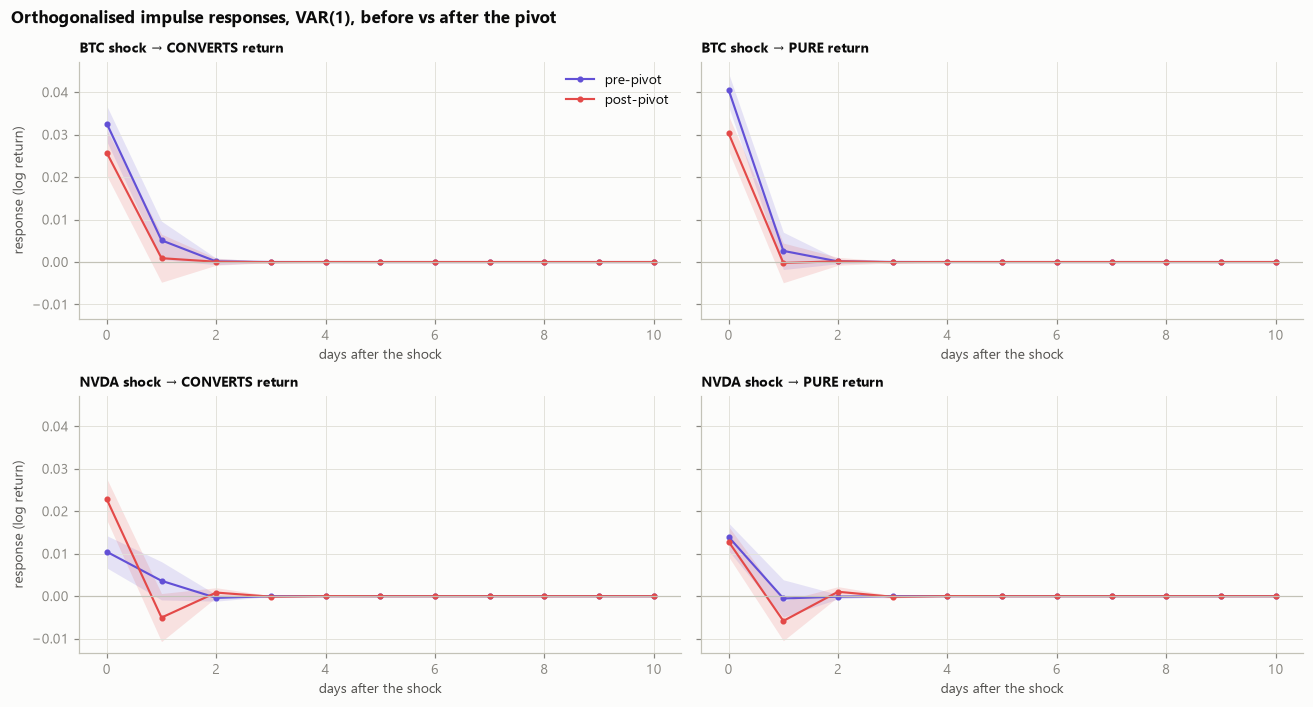

period            pre-pivot  post-pivot
shock response h                       
BTC   CONVERTS 0     0.0326      0.0257
               1     0.0051      0.0009
      PURE     0     0.0405      0.0303
               1     0.0026     -0.0002
NVDA  CONVERTS 0     0.0105      0.0228
               1     0.0036     -0.0050
      PURE     0     0.0140      0.0128
               1    -0.0005     -0.0058

In [6]:
# IRFs pre vs post for the 4 shock/response pairs that answer the research question.
irf = pd.concat([mv.impact_responses(vars_[n], periods=10).assign(period=n) for n in ("pre-pivot", "post-pivot")], ignore_index=True)
irf_full = mv.impact_responses(vars_["full"], periods=10).assign(period="full")
pd.concat([irf_full, irf]).to_csv(RES / "04_irf.csv", index=False)
cols = {"pre-pivot": plotting.SERIES[6], "post-pivot": plotting.SERIES[7]}
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharey=True)
for i, shock in enumerate(("BTC", "NVDA")):
    for j, resp in enumerate(("CONVERTS", "PURE")):
        ax = axes[i, j]
        for n, col in cols.items():
            k = irf[(irf["shock"] == shock) & (irf["response"] == resp) & (irf["period"] == n)]
            ax.plot(k["h"], k["irf"], marker="o", ms=3, color=col, label=n)
            ax.fill_between(k["h"], k["lower"], k["upper"], color=col, alpha=0.15, lw=0)
        ax.axhline(0, color=plotting.AXIS, lw=0.8)
        ax.set_title(f"{shock} shock → {resp} return", fontsize=9); ax.set_xlabel("days after the shock")
axes[0, 0].legend(loc="upper right"); axes[0, 0].set_ylabel("response (log return)"); axes[1, 0].set_ylabel("response (log return)")
fig.suptitle("Orthogonalised impulse responses, VAR(1), before vs after the pivot", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); print(plotting.save(fig, "fig_04_01_irf_pre_post")); plt.show()
irf[irf["h"] <= 1].pivot_table(index=["shock", "response", "h"], columns="period", values="irf", sort=False)[["pre-pivot", "post-pivot"]].round(4)

In [7]:
# Same-day impact with its 95 % band (h = 0), the cleanest pre/post comparison.
imp = pd.concat([irf_full, irf])
imp = imp[imp["h"] == 0][["period", "shock", "response", "irf", "lower", "upper"]]
imp

,period,shock,response,irf,lower,upper
0,full,BTC,CONVERTS,0.0305,0.0272,0.0338
11,full,BTC,PURE,0.0373,0.0344,0.0402
22,full,NVDA,CONVERTS,0.0146,0.0115,0.0176
33,full,NVDA,PURE,0.0137,0.0112,0.0161
0,pre-pivot,BTC,CONVERTS,0.0326,0.0284,0.0368
11,pre-pivot,BTC,PURE,0.0405,0.0366,0.0444
22,pre-pivot,NVDA,CONVERTS,0.0105,0.0067,0.0143
33,pre-pivot,NVDA,PURE,0.0140,0.0107,0.0172
44,post-pivot,BTC,CONVERTS,0.0257,0.0203,0.0311
55,post-pivot,BTC,PURE,0.0303,0.0261,0.0345


**Same-day effect (h = 0), response to a one-standard-deviation shock, in log return, with 95% bands:**

| Shock → response | Pre-pivot | Post-pivot | Change |
|---|---|---|---|
| BTC → CONVERTS | 0.0326 [0.0284; 0.0368] | 0.0257 [0.0203; 0.0311] | −21% |
| BTC → PURE | 0.0405 [0.0366; 0.0444] | 0.0303 [0.0261; 0.0345] | −25% |
| NVDA → CONVERTS | 0.0105 [0.0067; 0.0143] | **0.0228** [0.0179; 0.0277] | **× 2.2** |
| NVDA → PURE | 0.0140 [0.0107; 0.0172] | 0.0128 [0.0093; 0.0164] | ≈ stable |

* **Link with BTC.** The response to a BTC shock falls after the pivot **for both groups**, by similar proportions (−21% for CONVERTS, −25% for PURE). This loosening affects all miners, not only the converts: nothing here allows saying that the converts "let go" of BTC more than the others.
* **Link with NVDA.** The response of CONVERTS to an NVDA shock **doubles** (0.0105 → 0.0228), and the 95% bands do not overlap. PURE's does not move (0.0140 → 0.0128). This is **the only change specific to the converts**, and it goes in the direction of H2. The control works: it allows attributing this change to the business model rather than to the market as a whole.
* **Orders of magnitude after the pivot.** CONVERTS still reacts slightly more to BTC (0.0257) than to NVDA (0.0228): **BTC remains a major driver**, and NVDA has become a second one of comparable importance.
* **Dynamics.** Everything happens at h = 0. At h = 1 the response is small: −0.005 for NVDA → CONVERTS post-pivot, a small correction the next day. From h = 2 the response is zero.
* **Caution in interpretation.** With the chosen Cholesky order, the "NVDA shock" is the part of NVDA's return **not explained by BTC** the same day. Its effect therefore measures an exposure to NVDA **on top of** the exposure to BTC.

## 4. Cointegration on log prices (Johansen and Engle-Granger)

The four log prices are I(1) (Phase 2), so cointegration is the right question: do two non-stationary series have a **stable gap** in the long run?

* **Johansen, trace test** — H0: cointegration rank ≤ r. We test r = 0 then r = 1, and the chosen rank is the first r not rejected at 5%. **Maximum eigenvalue test** — H0: rank = r vs rank = r + 1.
* **Deterministic term: unrestricted constant** (Johansen case 3, `det_order = 0`). Why: log prices have a drift (BTC and NVDA rise over the period), so a constant is needed in the differenced equations. There is, however, no reason to add a deterministic trend in the equilibrium relationship between two prices.
* **Lags**: number of lagged differences chosen by BIC on the VECM (`select_order`), at least 1.
* **Engle-Granger** (robustness) — H0: no cointegration. The group is regressed on the reference with a constant, then the residuals are tested for a unit root (MacKinnon p-value).

In [8]:
# 4 pairs x 3 periods; k_ar_diff by BIC (min 1). Johansen rank by trace and by max-eigenvalue, plus Engle-Granger.
PAIRS = [("CONVERTS", "BTC"), ("PURE", "BTC"), ("CONVERTS", "NVDA"), ("PURE", "NVDA")]
LPER = mv.period_slices(lp.index, cfg["pivot_date"])
def coint_row(g, ref, idx, period):
    y = lp.loc[idx, [g, ref]]
    k = max(int(select_order(y.to_numpy(), maxlags=10, deterministic="co").bic), 1)
    return {"pair": f"{g}–{ref}", "period": period, "n": len(y), "k_ar_diff": k,
            **mv.johansen_pair(y, k_ar_diff=k), **mv.engle_granger(y[g], y[ref])}
coint_tab = pd.DataFrame([coint_row(g, r, idx, n) for g, r in PAIRS for n, idx in LPER.items()])
coint_tab["conclusion"] = np.where(coint_tab["rank_trace"] >= 1, "cointegrated (Johansen)",
                          np.where(coint_tab["EG_p"] < 0.05, "Engle-Granger only", "not cointegrated"))
coint_tab.to_csv(RES / "04_cointegration.csv", index=False)
coint_tab[["pair", "period", "n", "k_ar_diff", "trace_r0", "cv95_trace_r0", "trace_r1", "cv95_trace_r1", "maxeig_r0",
           "cv95_maxeig_r0", "rank_trace", "rank_maxeig", "EG_p", "conclusion"]].round(3)

,pair,period,n,k_ar_diff,trace_r0,cv95_trace_r0,trace_r1,cv95_trace_r1,maxeig_r0,cv95_maxeig_r0,rank_trace,rank_maxeig,EG_p,conclusion
0,CONVERTS–BTC,full,1225,1,10.139,15.494,2.424,3.842,7.715,14.264,0,0,0.661,not cointegrated
1,CONVERTS–BTC,pre-pivot,778,1,11.922,15.494,0.002,3.842,11.920,14.264,0,0,0.220,not cointegrated
2,CONVERTS–BTC,post-pivot,447,1,14.518,15.494,2.020,3.842,12.498,14.264,0,0,0.769,not cointegrated
3,PURE–BTC,full,1225,1,12.783,15.494,0.432,3.842,12.350,14.264,0,0,0.045,Engle-Granger only
4,PURE–BTC,pre-pivot,778,1,10.552,15.494,0.406,3.842,10.146,14.264,0,0,0.120,not cointegrated
5,PURE–BTC,post-pivot,447,1,8.029,15.494,1.391,3.842,6.638,14.264,0,0,0.514,not cointegrated
6,CONVERTS–NVDA,full,1225,1,16.632,15.494,1.525,3.842,15.107,14.264,1,1,0.260,cointegrated (Johansen)
7,CONVERTS–NVDA,pre-pivot,778,1,17.194,15.494,0.562,3.842,16.631,14.264,1,1,0.171,cointegrated (Johansen)
8,CONVERTS–NVDA,post-pivot,447,1,6.133,15.494,1.132,3.842,5.001,14.264,0,0,0.449,not cointegrated
9,PURE–NVDA,full,1225,1,14.366,15.494,0.186,3.842,14.180,14.264,0,0,0.022,Engle-Granger only


**Johansen trace test at 5% (critical value 15.49 for r = 0):**
* **CONVERTS–NVDA** is the only cointegrated pair: on the full sample (trace = 16.63) and **pre-pivot** (17.19). The maximum eigenvalue confirms (15.11 and 16.63, vs 14.26). **Post-pivot, no cointegration at all** (trace = 6.13).
* **CONVERTS–BTC** is cointegrated in **no** period (trace = 10.14 / 11.92 / 14.52). Engle-Granger confirms (p = 0.66 / 0.22 / 0.77).
* **PURE–BTC** is cointegrated in no period according to Johansen (12.78 / 10.55 / 8.03). Only Engle-Granger rejects H0, and only on the full sample (p = 0.045). Same pattern for PURE–NVDA (Engle-Granger p = 0.022 on the full sample, Johansen not).
* **Fragility, revealed by R.** The CONVERTS–NVDA trace statistic is identical in R, but `urca` uses a higher critical value (17.95) and therefore does not reject r = 0. The maximum eigenvalue test rejects in both languages. This cointegration is **borderline**.

**What this says about the hypotheses.**
* **H1** ("pure miners stay cointegrated with BTC") **is not supported**. Johansen finds no PURE–BTC cointegration, and only Engle-Granger on the full sample weakly suggests it (p = 0.045).
* **H2, long-run version** ("the converts lose their long-run link with BTC") **cannot be checked as such**: CONVERTS was never cointegrated with BTC, so there was no long-run anchor to lose.
* **The only long-run link detected**, CONVERTS–NVDA, exists **before** the pivot and **disappears after**. This is the opposite of what H2 expected.
* **An important limitation: the power of the test.** The post-pivot period has only 447 days (≈ 1.8 years). For a cointegration test that is short: the absence of cointegration after the pivot can reflect a lack of data as much as a real break.

## 5. VECM where Johansen finds cointegration

Estimated form, for the pair y = (group, reference): Δy_t = α (β′ y_{t−1}) + Γ Δy_{t−1} + c + ε_t.
* **β** is the cointegrating vector, normalised to 1 on the group: the equilibrium error is ECT = y_group − b · y_reference.
* **α** gives the adjustment coefficients: the share of the previous day's gap corrected each day. A negative α in the group's equation means the group returns towards equilibrium.
* **Half-life** = ln(0.5) / ln(1 + α) trading days: the time for a gap to be halved.

In [9]:
# Fit a VECM for every (pair, period) with Johansen trace rank >= 1; report beta, alpha (with p-values) and half-lives.
vecm_rows, vecms = [], {}
for _, row in coint_tab[coint_tab["rank_trace"] >= 1].iterrows():
    g, ref = row["pair"].split("–")
    y = lp.loc[LPER[row["period"]], [g, ref]]
    v = mv.fit_vecm(y, k_ar_diff=int(row["k_ar_diff"]), rank=1)
    vecms[(row["pair"], row["period"])] = (v, y)
    a, pa, b = v.alpha.ravel(), v.pvalues_alpha.ravel(), v.beta.ravel()
    vecm_rows.append({"pair": row["pair"], "period": row["period"], "k_ar_diff": int(row["k_ar_diff"]),
                      "beta_group": b[0], "beta_reference": b[1],
                      "alpha_group": a[0], "p_alpha_group": pa[0], "half-life group (d)": mv.half_life(a[0]),
                      "alpha_reference": a[1], "p_alpha_reference": pa[1], "half-life reference (d)": mv.half_life(a[1])})
vecm_tab = pd.DataFrame(vecm_rows)
vecm_tab.to_csv(RES / "04_vecm.csv", index=False)
vecm_tab.round(4)

,pair,period,k_ar_diff,beta_group,beta_reference,alpha_group,p_alpha_group,half-life group (d),alpha_reference,p_alpha_reference,half-life reference (d)
0,CONVERTS–NVDA,full,1,1.0,-0.9351,-0.0108,0.0003,64.0844,-0.0042,0.0057,162.9907
1,CONVERTS–NVDA,pre-pivot,1,1.0,-0.6462,-0.0151,0.0005,45.4082,-0.0075,0.0014,92.4849


figures\fig_04_02_vecm_equilibrium_error.png


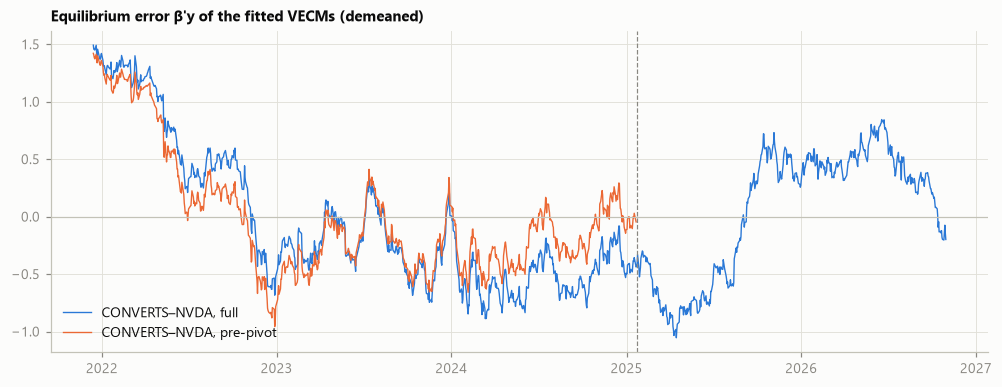

In [10]:
# Equilibrium error ECT = beta' y over time for each fitted VECM: it should look stationary if the pair is cointegrated.
if vecms:
    fig, ax = plt.subplots(figsize=(11, 3.8))
    for ((pair, per), (v, y)), col in zip(vecms.items(), plotting.SERIES):
        ect = y.to_numpy() @ v.beta.ravel()
        ax.plot(y.index, ect - ect.mean(), lw=0.9, color=col, label=f"{pair}, {per}")
    ax.axhline(0, color=plotting.AXIS, lw=0.8); ax.axvline(pd.Timestamp(cfg["pivot_date"]), color=plotting.MUTED, ls="--", lw=0.8)
    ax.set_title("Equilibrium error β'y of the fitted VECMs (demeaned)"); ax.legend(loc="lower left")
    print(plotting.save(fig, "fig_04_02_vecm_equilibrium_error")); plt.show()

**VECM CONVERTS–NVDA** (the only pairs cointegrated according to the statsmodels trace test):

| Period | β (NVDA) | α CONVERTS (p) | CONVERTS half-life | α NVDA (p) |
|---|---|---|---|---|
| Full | −0.935 | −0.0108 (p = 0.0003) | 64 days | −0.0042 (p = 0.0057) |
| Pre-pivot | −0.646 | −0.0151 (p = 0.0005) | 45 days | −0.0075 (p = 0.0014) |

* **Equilibrium relationship.** On the full sample, ln CONVERTS ≈ 0.94 · ln NVDA + constant: in the long run, the index follows NVDA almost proportionally.
* **Speed of return.** α_CONVERTS is negative and significant: when CONVERTS is "too high" relative to NVDA, it falls. But it corrects only about 1 to 1.5% of the gap per day, i.e. a half-life of **45 to 64 trading days** (2 to 3 months). The pull-back force exists but is slow.
* **α_NVDA is also negative and significant.** With a negative β, this means NVDA **moves away** from equilibrium instead of returning to it: all the adjustment comes from CONVERTS. Economically this makes sense (a small mining cap does not influence NVDA), but it confirms that the "relationship" is mostly CONVERTS slowly following a common trend.
* **Equilibrium error chart (fig. 04_02).** The gap β′y moves in very long waves: from +1.5 at the end of 2021 to ≈ −1 at the end of 2022, then ≈ −1 again in April 2025, and up to ≈ +0.8 in mid-2026 for the full sample. This is not the picture of a gap that quickly returns to zero. After the pivot, the gap rises clearly from mid-2025, when CONVERTS takes off (Phase 2), and stays away from zero for more than a year: consistent with the disappearance of cointegration after the pivot.
* **Cautious interpretation.** Before the pivot, CONVERTS and NVDA shared a large common cycle (2022 fall, 2023–2024 recovery), like all risky assets. This borderline "cointegration" may reflect that common cycle rather than an economic link. It should not be read as proof of AI exposure before the pivot.

## 6. Robustness: training sample only and other pivot dates

Two questions:
* do the post-pivot conclusions depend on the 123 test days?
* do they depend on the chosen date? We reuse candidates A = 2024-02-27 and C = 2025-08-13 from Phase 2.

In [11]:
# Re-run the key tests: Granger p-values (refs -> groups) and Johansen trace ranks, on alternative samples.
train_end = train.index[-1]
ALT = {"B: after 2025-01-22, train only": (pd.Timestamp(cfg["pivot_date"]), train_end),
       "A: before 2024-02-27": (None, pd.Timestamp("2024-02-26")), "A: after 2024-02-27": (pd.Timestamp("2024-02-27"), None),
       "C: before 2025-08-13": (None, pd.Timestamp("2025-08-12")), "C: after 2025-08-13": (pd.Timestamp("2025-08-13"), None)}
rob = []
for lab, (a, b) in ALT.items():
    rv = mv.fit_var(ret.loc[a:b], P)
    g = mv.granger_pairs(rv)
    row = {"sample": lab, "n": len(ret.loc[a:b])}
    for _, t in g[g["cause"].isin(["BTC", "NVDA"])].iterrows():
        row[f"Granger {t['cause']}→{t['effect']} p"] = t["p_value"]
    for gr_, ref in PAIRS:
        y = lp.loc[a:b, [gr_, ref]]
        k = max(int(select_order(y.to_numpy(), maxlags=10, deterministic="co").bic), 1)
        row[f"Johansen rank {gr_}–{ref}"] = mv.johansen_pair(y, k_ar_diff=k)["rank_trace"]
    rob.append(row)
rob = pd.DataFrame(rob)
rob.to_csv(RES / "04_robustness.csv", index=False)
rob.set_index("sample").T.round(4)

sample,"B: after 2025-01-22, train only",A: before 2024-02-27,A: after 2024-02-27,C: before 2025-08-13,C: after 2025-08-13
n,324.0000,551.0000,673.0000,917.0000,307.0000
Granger BTC→CONVERTS p,0.1087,0.5231,0.7094,0.7538,0.1981
Granger BTC→PURE p,0.0843,0.3094,0.9858,0.6300,0.2962
Granger NVDA→CONVERTS p,0.2902,0.7132,0.2804,0.7409,0.2278
Granger NVDA→PURE p,0.1119,0.2933,0.0970,0.2293,0.0728
Johansen rank CONVERTS–BTC,0.0000,0.0000,0.0000,0.0000,2.0000
Johansen rank PURE–BTC,0.0000,0.0000,0.0000,0.0000,0.0000
Johansen rank CONVERTS–NVDA,0.0000,0.0000,0.0000,1.0000,0.0000
Johansen rank PURE–NVDA,0.0000,0.0000,2.0000,0.0000,0.0000


* **Post-pivot, training sample only (324 days).** No significant Granger test (lowest: BTC → PURE, p = 0.084) and no cointegration. The post-pivot conclusions therefore do not depend on the test days.
* **Other pivot dates.**
  * With A (2024-02-27) and C (2025-08-13), no "reference → group" Granger test is significant at 5% (lowest: NVDA → PURE, p = 0.073 after C).
  * CONVERTS–NVDA cointegration reappears before C (rank 1), which confirms that this link belongs to the earlier period.
* **Johansen ranks equal to 2** (CONVERTS–BTC after C, PURE–NVDA after A). A rank of 2 would mean that both log prices are **stationary**, which contradicts the Phase 2 tests. These are small-sample artefacts (307 and 673 days), not interpretable results.

**Conclusion.** The two main results (no Granger causality, no cointegration after the pivot) depend neither on the pivot date nor on including the test data.

## 7. Answer to the research question (in plain words)

**Did the converts let go of Bitcoin to attach themselves to NVIDIA? A nuanced answer.** It depends on the horizon.

1. **Same day (short term): yes for NVDA, not specifically for BTC.**
   * After the pivot, the sensitivity of CONVERTS to an NVDA shock **doubles** (0.0105 → 0.0228, disjoint bands), while PURE's does not change. This change is **specific to the converts**, consistent with H2.
   * The sensitivity to BTC falls, but as much for PURE as for CONVERTS (−25% and −21%). There is therefore no specific decoupling from BTC.
   * BTC remains, narrowly, the converts' first driver (0.0257 vs 0.0228 for NVDA).
2. **From one day to the next (predictability, Granger): nothing changes.** Neither BTC nor NVDA predicts the converts, before or after the pivot.
3. **In the long run (cointegration): the hypothesis is not confirmed.**
   * The converts were **never** cointegrated with BTC.
   * The only long-run link, with NVDA, is borderline, exists **before** the pivot and disappears **after**.
   * The post-pivot period (447 days) is short for this kind of test.

**Is the pure-miner group a good control?**
* **Yes for the short term.** Its sensitivities behave like those of the converts before the pivot, and it does not show the jump towards NVDA. It is thanks to it that we can say this jump is specific to the converts.
* **No for the long term.** H1 is not supported: PURE is not cointegrated with BTC according to Johansen. The control is therefore not "anchored" to BTC as assumed.

**In one sentence:** the data show a **new daily exposure of the converts to NVIDIA** after early 2025, which adds to their link with Bitcoin without replacing it. They do **not** show a long-run break with Bitcoin, since no such link existed in the first place. The evidence is **mixed**: the story "the miners left Bitcoin for AI" is only partly true, in the sense of an additional exposure, not a replacement.

## 8. Forecasts h = 5 and h = 10 for CONVERTS (VAR and VECM)

Same protocol as in Phase 3: parameters estimated **on the training sample only**, rolling origins (last training day, then each test day), horizons 1 to 10, values in index points, 95% intervals. Common format (`results/forecasts_var.csv`, `results/forecasts_vecm.csv`).

* **`var1`**: VAR(1) on the returns of the four series, estimated on the whole training sample. The forecast log level is the last log level plus the sum of forecast returns. The variance of the cumulated error is Σ_i C_i Σ C_i′, with C_i = Ψ_0 + … + Ψ_i (the MA(∞) coefficients of the VAR).
* **`var1_post`**: the same VAR(1), estimated only on the **post-pivot** part of the training sample (324 days). It tests whether information on the recent regime helps forecasting.
* **`vecm_<reference>`**: VECM(group, reference) estimated on the training sample, for each reference with which CONVERTS is cointegrated **on the training sample** (Johansen test below). Its forecasts are made in levels, from its VAR-in-levels form.

The hand-written calculations are checked against `statsmodels` (`forecast`, `predict`) at the first origin.

In [12]:
# Fit on TRAIN only (no test information in any coefficient), then check cointegration on train for the VECM candidates.
H = 10
origins = panel.index[len(train) - 1: len(panel) - 1]
ret_tr = ret.loc[:train_end]
v_tr = mv.fit_var(ret_tr, P)
v_post = mv.fit_var(ret_tr.loc[cfg["pivot_date"]:], P)
fc_var = pd.concat([mv.var_return_forecasts(v_tr, ret, lp["CONVERTS"], "CONVERTS", origins, H, "var1"),
                    mv.var_return_forecasts(v_post, ret, lp["CONVERTS"], "CONVERTS", origins, H, "var1_post")], ignore_index=True)
# Check the hand-written recursion against statsmodels at the first origin.
ref = v_tr.forecast(ret_tr.to_numpy()[-1:], H)[:, V.index("CONVERTS")]
own = np.log(fc_var[(fc_var["model"] == "var1") & (fc_var["origin"] == origins[0])]["y_pred"].to_numpy())
assert np.allclose(own, lp.loc[train_end, "CONVERTS"] + np.cumsum(ref))
fc_var.to_csv(RES / "forecasts_var.csv", index=False, date_format="%Y-%m-%d")

coint_train = pd.DataFrame([coint_row("CONVERTS", r, lp.loc[:train_end].index, "apprentissage") for r in ("BTC", "NVDA")])
coint_train[["pair", "n", "k_ar_diff", "trace_r0", "cv95_trace_r0", "rank_trace", "rank_maxeig", "EG_p"]].round(3)

,pair,n,k_ar_diff,trace_r0,cv95_trace_r0,rank_trace,rank_maxeig,EG_p
0,CONVERTS–BTC,1102,1,9.619,15.494,0,0,0.871
1,CONVERTS–NVDA,1102,1,16.091,15.494,1,0,0.481


In [13]:
# VECM forecasts for every reference CONVERTS is cointegrated with on the train sample (none -> no VECM, said explicitly).
fc_vecm, vecm_train = [], []
for _, row in coint_train[coint_train["rank_trace"] >= 1].iterrows():
    ref_name = row["pair"].split("–")[1]
    y_tr = lp.loc[:train_end, ["CONVERTS", ref_name]]
    vt = mv.fit_vecm(y_tr, k_ar_diff=int(row["k_ar_diff"]), rank=1)
    f = mv.vecm_level_forecasts(vt, lp[["CONVERTS", ref_name]], "CONVERTS", origins, H, f"vecm_{ref_name.lower()}")
    pr, lo, up = vt.predict(H, alpha=0.05)
    assert np.allclose(np.log(f[f["origin"] == origins[0]]["y_pred"].to_numpy()), pr[:, 0])
    fc_vecm.append(f)
    vecm_train.append({"pair": row["pair"], "beta": vt.beta.ravel().round(4).tolist(), "alpha": vt.alpha.ravel().round(5).tolist(),
                       "p_alpha": vt.pvalues_alpha.ravel().round(4).tolist(), "half-life CONVERTS (d)": mv.half_life(vt.alpha.ravel()[0])})
fc_vecm = pd.concat(fc_vecm, ignore_index=True) if fc_vecm else pd.DataFrame(columns=arima.FORECAST_COLUMNS)
fc_vecm.to_csv(RES / "forecasts_vecm.csv", index=False, date_format="%Y-%m-%d")
print("VECM models:", fc_vecm["model"].unique().tolist() if len(fc_vecm) else "none (no cointegration on train)")
pd.DataFrame(vecm_train)

VECM models: ['vecm_nvda']


,pair,beta,alpha,p_alpha,half-life CONVERTS (d)
0,CONVERTS–NVDA,"[1.0, -0.9845]","[-0.0103, -0.0042]","[0.0007, 0.0084]",66.8948


In [14]:
# Preview of accuracy at h = 5 / 10 next to the random walk of Phase 3 (full evaluation and DM tests in Phase 7).
rw = pd.read_csv(RES / "forecasts_arima.csv", parse_dates=["date", "origin"]).query("series == 'CONVERTS' and model == 'rw'")
allfc = pd.concat([rw, fc_var, fc_vecm], ignore_index=True)
sc = arima.quick_scores(allfc)
sc.to_csv(RES / "04_forecast_scores_preview.csv", index=False)
sc

,model,series,horizon,n_origins,RMSE,MAE,MAPE_%,coverage_95%
0,rw,CONVERTS,5,119,28.7678,23.4698,10.4713,96.6387
1,rw,CONVERTS,10,114,36.0976,28.2671,13.6126,98.2456
2,var1,CONVERTS,5,119,29.1518,23.8919,10.6853,99.1597
3,var1,CONVERTS,10,114,37.0958,29.1729,14.1061,98.2456
4,var1_post,CONVERTS,5,119,30.4092,25.2856,11.4669,96.6387
5,var1_post,CONVERTS,10,114,41.7079,33.0626,16.2694,93.8596
6,vecm_nvda,CONVERTS,5,119,27.8625,22.3777,9.9350,97.4790
7,vecm_nvda,CONVERTS,10,114,33.7762,27.0014,12.7814,98.2456


figures\fig_04_03_forecasts_h5.png


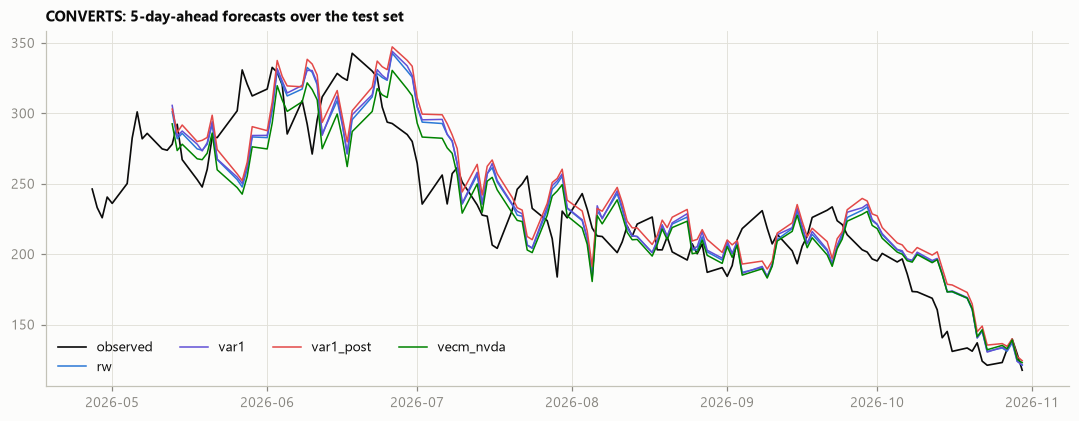

In [15]:
# 5-day-ahead forecasts of every model over the test set vs the observed index.
fig, ax = plt.subplots(figsize=(12, 4.2))
obs = np.exp(lp["CONVERTS"]).loc[test.index[0] - pd.Timedelta(days=10):]
ax.plot(obs.index, obs, color=plotting.INK, lw=1.1, label="observed")
for m, col in zip(allfc["model"].unique(), [plotting.CORE["CONVERTS"], plotting.SERIES[6], plotting.SERIES[7], plotting.SERIES[5]]):
    k = allfc[(allfc["model"] == m) & (allfc["horizon"] == 5)]
    ax.plot(k["date"], k["y_pred"], lw=1, color=col, label=m)
ax.set_title("CONVERTS: 5-day-ahead forecasts over the test set"); ax.legend(loc="lower left", ncol=4)
print(plotting.save(fig, "fig_04_03_forecasts_h5")); plt.show()

**Cointegration on the training sample.**
* CONVERTS–NVDA: trace = 16.09 > 15.49, so rank 1 (but the maximum eigenvalue test does not reject, another borderline case). A VECM is estimated: β = −0.98, α_CONVERTS = −0.0103 (p = 0.0007), half-life 67 days.
* CONVERTS–BTC: not cointegrated (trace = 9.62).

**Accuracy overview** (RMSE in index points; 119 origins at h = 5, 114 at h = 10):

| Model | RMSE h=5 | RMSE h=10 | MAPE h=5 | MAPE h=10 |
|---|---|---|---|---|
| rw (Phase 3) | 28.77 | 36.10 | 10.5% | 13.6% |
| var1 | 29.15 | 37.10 | 10.7% | 14.1% |
| var1_post | 30.41 | 41.71 | 11.5% | 16.3% |
| vecm_nvda | **27.86** | **33.78** | **9.9%** | **12.8%** |

* **VARs on returns do not beat the random walk.** This makes sense, since the criteria chose p = 0. The VAR estimated on the recent regime only is the worst: less data, hence noisier coefficients.
* **The CONVERTS–NVDA VECM does better than the random walk** (RMSE −3% at h = 5, −6% at h = 10). It is the only model so far to beat it, thanks to the pull back towards NVDA.
* **This is not yet proof.** The cointegration is borderline, the test is short (123 days), and the difference is not yet tested. The Diebold-Mariano test of Phase 7 will say whether it is significant.

## Phase 4 summary

1. **No usable dynamics**: the information criteria choose p = 0, and no "reference → group" Granger causality is robust (BTC → CONVERTS: p = 0.55 / 0.77 / 0.091).
2. **The link is contemporaneous**: after the pivot, the response of CONVERTS to an NVDA shock doubles (0.0105 → 0.0228, disjoint bands), with no change for PURE. The response to a BTC shock falls for both groups (−21% and −25%).
3. **Cointegration**: never between CONVERTS and BTC; PURE–BTC only according to Engle-Granger (p = 0.045, weak H1). CONVERTS–NVDA is cointegrated pre-pivot only, and borderline (R: trace below urca's critical value).
4. **VECM CONVERTS–NVDA**: half-life of 45 to 64 days; the only model that beats the random walk in forecasting (RMSE 27.9 vs 28.8 at h = 5, 33.8 vs 36.1 at h = 10), significance to be tested in Phase 7.
5. **Answer**: an additional daily exposure to NVDA appears for the converts, but the link with BTC is not replaced. The evidence is mixed, and R confirms all results except the borderline nature of the CONVERTS–NVDA cointegration.